# **Final Year Project - Year 4 Software Development**
## Librosa Research Notebook
*By Mark Lambert - C00192497*

---

The following notebook is based on work done towards the end of my internship. 
The initial prototype was developed in PyCharm, so I have spent time to convert that python file to a Jupyter Notebook.
    Librosa, matplotlib and numpy are the libraries used for this notebook

In [5]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

Load the clip and the samplerate of the clip using ```librosa.load```

In [56]:
aMajor, samplerate = librosa.load('clips/Amaj.wav', sr=None)

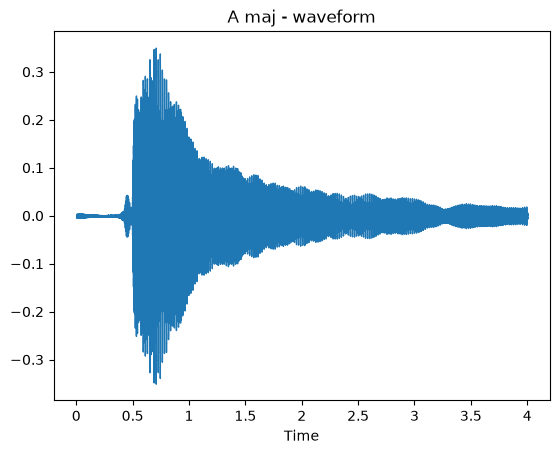

In [57]:
librosa.display.waveshow(aMajor, sr=samplerate)
plt.title('A maj - waveform')
plt.show()

Pass the loaded clip into librosa to produce a ```chromagram```, display the chromagram using ```librosa.display.specshow```, which displays the chromagram w/ automatic axis assignment and labels

In [58]:
chroma = librosa.feature.chroma_cqt(y=aMajor, sr=samplerate)

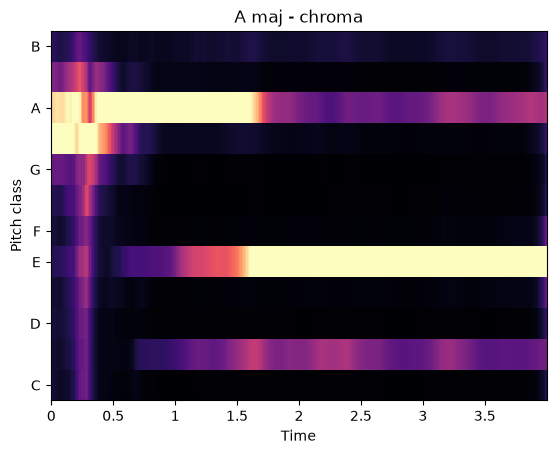

In [59]:
librosa.display.specshow(chroma, y_axis='chroma', x_axis='time', sr=samplerate)
plt.title('A maj - chroma')
plt.show()

A small template dictionary of chords represented as **arrays split into 12 pitch classifications**

In [60]:
# 0=C, 1=C#, 2=D, 3=D#, 4=E, 5=F, 6=F#, 7=G, 8=G#, 9=A, 10=A#, 11=B, exactly like the 12 pitch classes from a chroma
chord_templates = {
    'C':  [1,0,0,0,1,0,0,1,0,0,0,0],
    'G':  [0,0,1,0,0,0,0,1,0,0,0,1],
    'D':  [0,0,1,0,0,0,1,0,0,1,0,0],
    'Em': [0,0,0,0,1,0,0,1,0,0,0,1],
    'Am': [1,0,0,0,1,0,0,0,0,1,0,0],
    'F':  [1,0,0,0,0,1,0,0,0,1,0,0],
    'A':  [0,1,0,0,1,0,0,0,0,1,0,0],
}

Chord Detection function, takes in chroma_frame, which is a frame of the clip and performs ```cosin similarity``` on the audio clips ```chroma frame``` against the ```template chords```. The output is the best matched chord, with the name taken from the template and the certainty of the algorithms assumption

In [61]:
def detect_chord(chroma_frame):
    '''
    :param chroma_frame: section of audio as a chroma, to analyse the notes present and find the best
                        chord match
    :return: the best match chord, taken from the average chroma frame
    '''

    best_match = None
    best_score = -1

    for name, template in chord_templates.items():
        #Cosine similarity: dot product of the the chroma_frame vector and the template of chords vector divided by the product of their magnitudes
        score = np.dot(chroma_frame, template) / (np.linalg.norm(chroma_frame) * np.linalg.norm(template))
        if score > best_score:
            best_match = name
            best_score = score

    return best_match, best_score

```avg_chroma``` takes averages the chromagram for the audio track into one 12 value vector representing the whole clip. (12 pitch classes)

In [62]:
avg_chroma = np.mean(chroma, axis=1)
chord, score = detect_chord(avg_chroma)
# print w/ score rounded to two decimal places
print(f"The chord is: {chord} , Certainty: {round(score, 2)}")

The chord is: A , Certainty: 0.92


In [63]:
cToG, sr2 = librosa.load('clips/C_to_G.wav', sr=None)

In [64]:
# Compute a separate chromagram for this clip
chroma2 = librosa.feature.chroma_cqt(y=cToG, sr=sampleRate2)

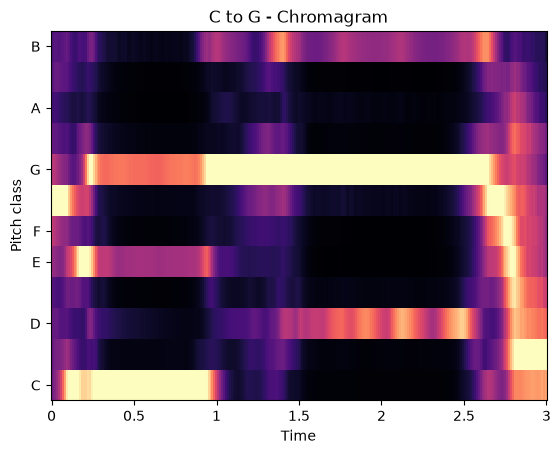

In [70]:
librosa.display.specshow(chroma2, y_axis='chroma', x_axis='time', sr=samplerate)
plt.title('C to G - Chromagram')
plt.show()

[This freeCodeCamp article](https://www.freecodecamp.org/news/use-python-to-detect-music-onsets/#:~:text=Finally) details the process of using librosa to detect music **onsets**. An onset is the musical term for the **beginning of a note.**

In [71]:
onset_frames = librosa.onset.onset_detect(y=cToG, sr=sampleRate2, units='time')
onset_times = librosa.frames_to_time(onset_frames)
onset_times

array([0.00077098, 0.00267574, 0.00403628, 0.00535147, 0.00671202,
       0.02290249, 0.02829932, 0.03097506, 0.03179138, 0.03287982,
       0.0339229 , 0.03501134, 0.03609977, 0.05873016, 0.05981859,
       0.06494331])

Redrawing the above chromagram shows the onset times, note the large gaps when not transitioning

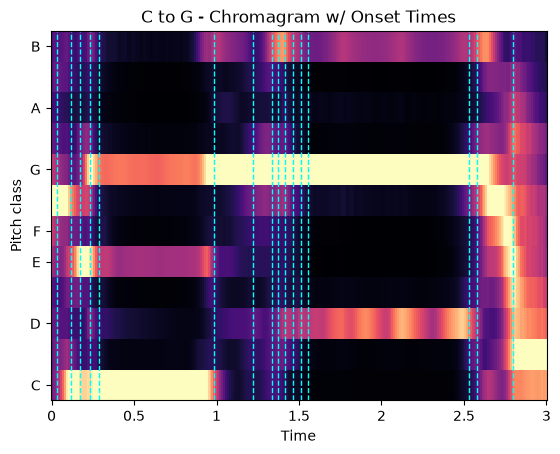

In [73]:
plt.vlines(onset_frames, ymin=-0.5, ymax=11.5, color='cyan', linestyle='--', linewidth=1)
librosa.display.specshow(chroma2, y_axis='chroma', x_axis='time', sr=samplerate)
plt.title('C to G - Chromagram w/ Onset Times')
plt.show()